In [14]:
import wfdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

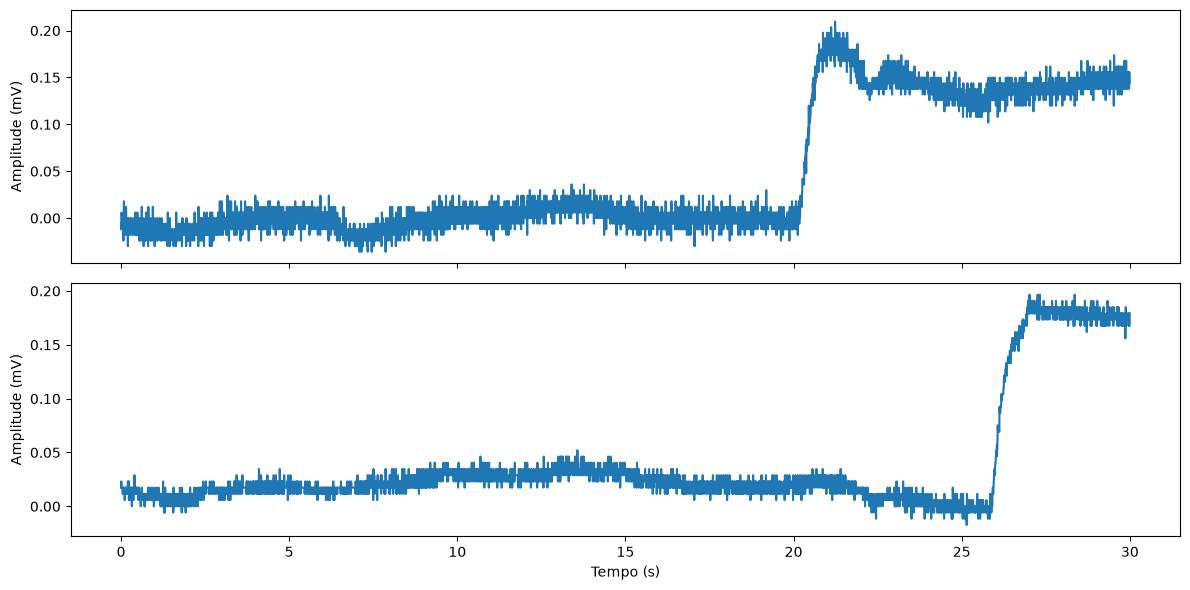

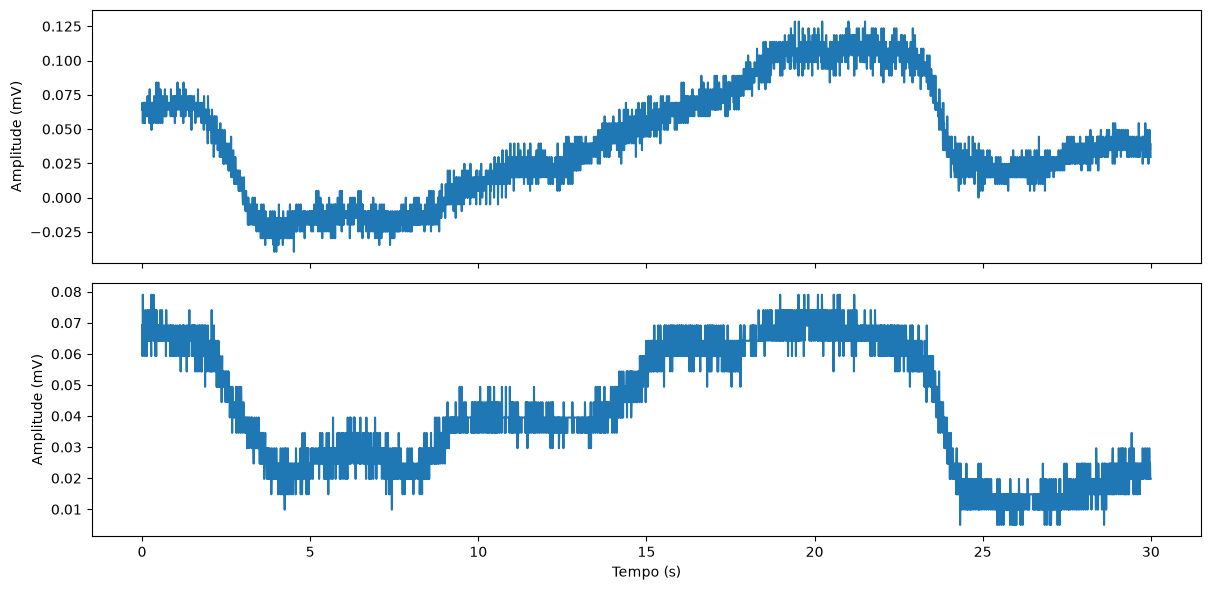

In [17]:
registros = ['00', '01']
dados = {}
res_tabela = []

for id in registros:
    head = wfdb.rdheader(id, pn_dir='ltafdb/1.0.0')

    amostragem = head.fs * 30
    record = wfdb.rdrecord(id, pn_dir='ltafdb/1.0.0', sampfrom=0, sampto=amostragem)
    
    ann = wfdb.rdann(id, 'atr', pn_dir='ltafdb/1.0.0', sampfrom=0, sampto=amostragem)
    
    tempo = np.arange(amostragem)/head.fs

    dados[id] = {'head': head, 'record': record, 'ann': ann, 'tempo' : tempo}

    res_tabela.append({
        'registro' : id,
        'frequencia' : head.fs,
        'qtd_amostras' : head.sig_len,
        'derivacoes' : head.n_sig,
        'nome' : head.sig_name,
        'unidades' : head.units
    })

    fig, graf = plt.subplots(2,1, figsize=(12,6), sharex=True)

    graf[0].plot(tempo, record.p_signal[:,0])
    graf[0].set_ylabel(f"Amplitude ({head.units[0]})")
    graf[1].plot(tempo, record.p_signal[:,1])
    graf[1].set_ylabel(f"Amplitude ({head.units[1]})")
    graf[1].set_xlabel("Tempo (s)")
    plt.tight_layout()
    plt.savefig(f"../figures/{id}_30s.png", dpi=300)
    plt.show()
    plt.close(fig)